# ДЗ 1. CUB-200-2011: итеративная аугментация, разморозка слоёв и псевдолейблинг

Задача: классифицировать фотографии птиц на 200 видов и на этом примере сравнить техники обучения с занятия:

- итеративная разморозка слоёв с адаптивным lr;
- итеративная аугментация;
- псевдолейблинг.

Архитектуры взял все три со слайда с экспериментами: ResNet-50, EfficientNet-B7 и EfficientNetV2-S. Веса предобучены на ImageNet и берутся из torchvision.

CUB-200-2011 это fine-grained датасет: многие виды отличаются мелкими деталями вроде формы клюва или полосок на крыльях, а на класс приходится всего около 60 фотографий. Часть трейна я отдаю под псевдолейблинг как неразмеченную, поэтому для обучения остаётся около 19 размеченных картинок на класс.

Для ориентира: в [статье про NTS-Net](https://arxiv.org/abs/1809.00287) ResNet-50 на официальном разбиении (30 картинок на класс в трейне) и входе 448 x 448 даёт 84.5% accuracy. У меня разметки меньше и вход 224 x 224, поэтому жду заметно ниже, где-то 75-80%.

Для каждой архитектуры 4 режима, каждый следующий добавляет одну технику к предыдущему, как в таблице со слайда:

| режим | что добавляется |
|---|---|
| `baseline` | обычный fine-tuning: вся сеть учится с первой эпохи с одним lr, без аугментаций |
| `unfreeze` | итеративная разморозка: сначала только голова, потом по одной группе блоков за эпоху, у каждой группы свой lr |
| `augment` | итеративная аугментация: каждые 5 эпох добавляется новый тип преобразований |
| `pseudo` | псевдолейблинг: с 11-й эпохи к размеченным картинкам добавляются картинки из пула с метками от самой модели |

Все режимы учатся 20 эпох с батчем 32, каждый запуск повторяю на 3 сидах. В таблицах дальше среднее ± std по сидам. Считал на Kaggle на двух T4.

## Импорты

In [1]:
import collections
import copy
import math
import queue
import threading
import time
from concurrent.futures import ThreadPoolExecutor
from dataclasses import dataclass
from pathlib import Path

In [2]:
import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from sklearn.metrics import confusion_matrix, f1_score, log_loss
from sklearn.model_selection import train_test_split

In [3]:
import torch
from torch import nn
from torchvision import models
from torchvision.transforms import v2

## Настройки

In [4]:
DATASET_HANDLE = "coolerextreme/cub-200-2011"
KAGGLE_INPUT_DIR = Path("/kaggle/input")
RESULTS_DIR = Path("results")

SPLIT_SEED = 42
SEEDS = [0, 1, 2]
TEST_SHARE = 0.25
VAL_SHARE = 0.1
UNLABELED_SHARE = 0.5

IMAGE_SIZE = 224
BATCH_SIZE = 32
EVAL_BATCH_SIZE = 64

EPOCHS = 20
BASE_LR = 1e-4
HEAD_LR = 5e-4
LR_DECAY = 0.5
WEIGHT_DECAY = 1e-4
AUG_LEVEL_EPOCHS = 5

PSEUDO_UPDATE_EPOCHS = [10, 15]
PSEUDO_THRESHOLD = 0.9
PSEUDO_WEIGHT = 1.0

ARCHS = ["resnet50", "efficientnet_b7", "efficientnet_v2_s"]
MODES = ["baseline", "unfreeze", "augment", "pseudo"]

if torch.cuda.is_available():
    DEVICES = [
        torch.device(f"cuda:{i}") for i in range(torch.cuda.device_count())
    ]
elif torch.backends.mps.is_available():
    DEVICES = [torch.device("mps")]
else:
    DEVICES = [torch.device("cpu")]
USE_AMP = DEVICES[0].type == "cuda"

IMAGENET_MEAN = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1) * 255
IMAGENET_STD = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1) * 255
ARCH_TITLES = {
    "resnet50": "ResNet-50",
    "efficientnet_b7": "EfficientNet-B7",
    "efficientnet_v2_s": "EfficientNetV2-S",
}
MODE_COLORS = dict(zip(MODES, ["#7f7f7f", "#1f77b4", "#2ca02c", "#d62728"]))
print("Devices:", ", ".join(
    torch.cuda.get_device_name(device) if device.type == "cuda"
    else device.type
    for device in DEVICES
))

Devices: Tesla T4, Tesla T4


## Данные

[CUB-200-2011 на Kaggle](https://www.kaggle.com/datasets/coolerextreme/cub-200-2011): 11 788 фотографий 200 видов птиц. В этой версии картинки уже лежат тензорами 256 x 256, а в `metadata.pth` есть id картинок и их классы.

Разбиение train/test в этой версии сделано для генерации картинок по тексту: виды в трейне и тесте не пересекаются. Для классификации оно не подходит, поэтому все картинки объединяю и делю заново.

In [5]:
if KAGGLE_INPUT_DIR.exists():
    dataset_root = KAGGLE_INPUT_DIR
else:
    dataset_root = Path(kagglehub.dataset_download(DATASET_HANDLE))
dataset_dir = next(dataset_root.rglob("metadata.pth")).parent

# metadata.pth keeps python containers next to the tensors, so the safe
# loader needs these two types to be allowed explicitly.
torch.serialization.add_safe_globals([frozenset, collections.Counter])
metadata = torch.load(dataset_dir / "metadata.pth", weights_only=True)
images = torch.cat(
    [
        torch.load(dataset_dir / f"imgs_{part}_256x256.pth", weights_only=True)
        for part in ("train_val", "test")
    ]
)
image_ids = metadata["train_val_img_ids"] + metadata["test_img_ids"]

class_ids = sorted(metadata["class_id_to_class_name"])
class_names = [
    metadata["class_id_to_class_name"][class_id].replace("_", " ")
    for class_id in class_ids
]
num_classes = len(class_names)
label_by_class_id = {
    class_id: label for label, class_id in enumerate(class_ids)
}
images_df = pd.DataFrame(
    {
        "image_id": image_ids,
        "label": [
            label_by_class_id[metadata["img_id_to_class_id"][image_id]]
            for image_id in image_ids
        ],
    }
)
images_df["class_name"] = images_df.label.map(dict(enumerate(class_names)))
print(
    f"Images: {tuple(images.shape)}, {images.dtype}, "
    f"{images.numel() / 1024 ** 3:.2f} GB, classes: {num_classes}"
)

Images: (11788, 3, 256, 256), torch.uint8, 2.16 GB, classes: 200


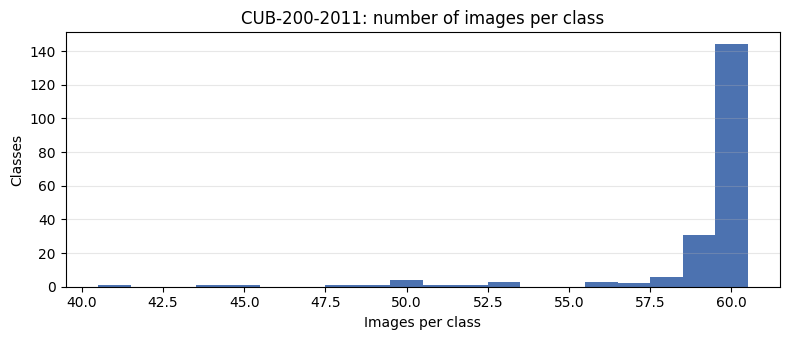

In [6]:
class_counts = images_df.label.value_counts()

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(class_counts, bins=range(class_counts.min(), class_counts.max() + 2),
        color="#4c72b0", align="left")
ax.set(
    xlabel="Images per class",
    ylabel="Classes",
    title="CUB-200-2011: number of images per class",
)
ax.grid(axis="y", alpha=0.3)
fig.tight_layout()
plt.show()

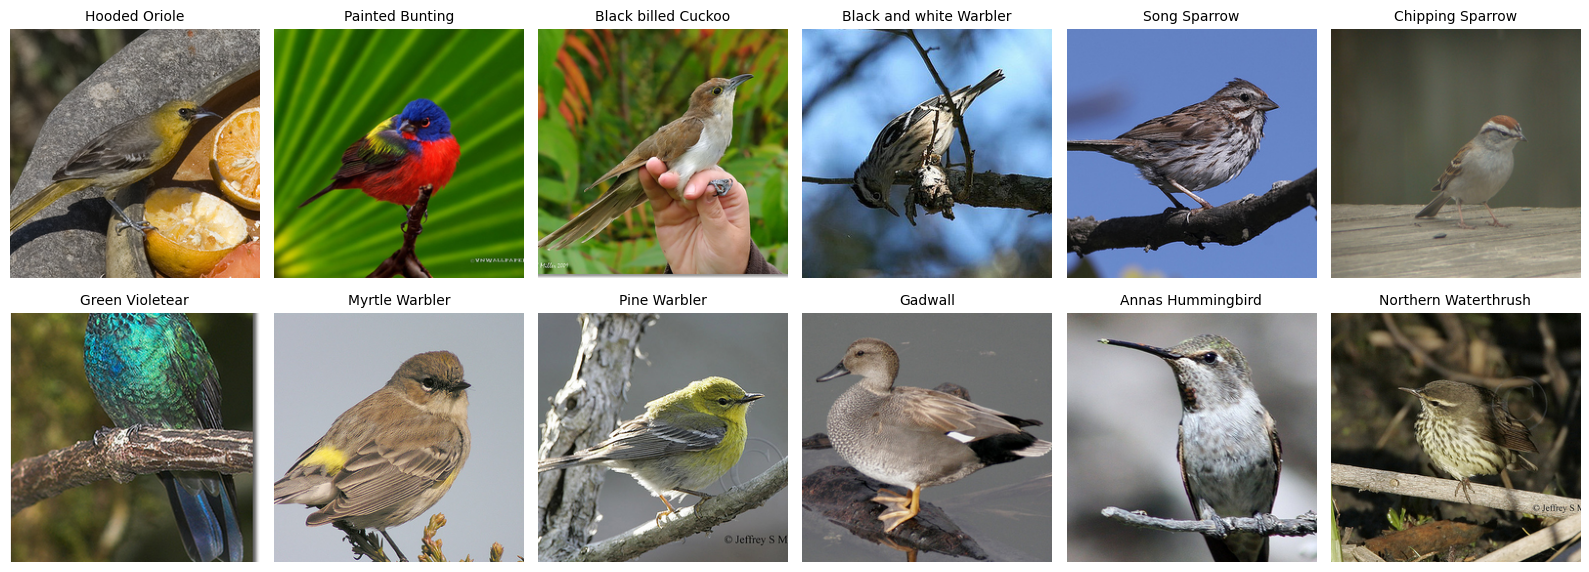

In [7]:
examples = images_df.groupby("label").sample(1, random_state=SPLIT_SEED)
examples = examples.sample(12, random_state=SPLIT_SEED)

fig, axes = plt.subplots(2, 6, figsize=(16, 6))
for ax, row in zip(axes.flat, examples.itertuples()):
    ax.imshow(images[row.Index].permute(1, 2, 0))
    ax.set_title(row.class_name, fontsize=10)
    ax.axis("off")
fig.tight_layout()
plt.show()

Классы почти сбалансированы: у большинства видов по 60 фотографий, минимум 41. Основная метрика accuracy, macro-F1 считаю для контроля.

### Разбиение

Всё со стратификацией по классам:

- `test`: 25%, только для итоговой оценки;
- `validation`: 10%, по ней выбирается лучшая эпоха;
- `labeled`: половина оставшегося, на ней идёт обучение;
- `unlabeled`: вторая половина. Её метки в обучении не используются, они нужны только чтобы проверить качество псевдометок.

Разбиение одно для всех запусков.

In [8]:
train_df, test_df = train_test_split(
    images_df,
    test_size=TEST_SHARE,
    stratify=images_df.label,
    random_state=SPLIT_SEED,
)
train_df, val_df = train_test_split(
    train_df,
    test_size=VAL_SHARE / (1 - TEST_SHARE),
    stratify=train_df.label,
    random_state=SPLIT_SEED,
)
labeled_df, unlabeled_df = train_test_split(
    train_df,
    test_size=UNLABELED_SHARE,
    stratify=train_df.label,
    random_state=SPLIT_SEED,
)

splits = {
    "labeled": labeled_df,
    "unlabeled": unlabeled_df,
    "validation": val_df,
    "test": test_df,
}
all_indices = np.concatenate([frame.index for frame in splits.values()])
assert len(all_indices) == len(set(all_indices)) == len(images_df)

split_rows = []
for name, frame in splits.items():
    per_class = frame.label.value_counts()
    split_rows.append(
        {
            "split": name,
            "images": len(frame),
            "share, %": 100 * len(frame) / len(images_df),
            "classes": len(per_class),
            "min / class": per_class.min(),
            "median / class": per_class.median(),
            "max / class": per_class.max(),
        }
    )
display(pd.DataFrame(split_rows).set_index("split").round(1))

,images,"share, %",classes,min / class,median / class,max / class
split,,,,,,
labeled,3831,32.5,200,14,19.0,20
unlabeled,3831,32.5,200,13,19.0,20
validation,1179,10.0,200,4,6.0,6
test,2947,25.0,200,10,15.0,15


## Итеративная аугментация

Аугментации добавляются по одной группе каждые 5 эпох:

| эпохи | уровень | что добавляется |
|---|---|---|
| 1-5 | 0 | случайный кроп (60-100% площади) и горизонтальное отражение |
| 6-10 | 1 | сдвиг до 10% и поворот до 15 градусов |
| 11-15 | 2 | изменение яркости и контраста |
| 16-20 | 3 | вырезание случайного прямоугольника |

В начале модель учится на почти чистых картинках, а когда она уже нормально классифицирует, задача постепенно усложняется. В режимах `baseline` и `unfreeze` аугментаций нет, там всегда центральный кроп.

Из цветовых аугментаций оставил только яркость и контраст. Сначала я брал ещё изменение оттенка и насыщенности и перевод в ч/б, как в обычных пайплайнах, но на пробном запуске ResNet-50 с ними теряла на валидации около 2% относительно варианта без аугментаций. У птиц цвет оперения один из главных признаков вида, и такие преобразования по сути портят метку.

Аугментации применяются к каждой картинке отдельно уже на GPU. На Kaggle всего 4 ядра CPU, и в одном потоке на CPU получалось около 130 картинок в секунду, меньше, чем ResNet-50 успевает обучаться на T4.

Ниже одна картинка из трейна на каждом уровне, в первом столбце без аугментаций.

In [9]:
AUG_LEVEL_NAMES = [
    "crop + flip",
    "+ shift, rotation",
    "+ brightness, contrast",
    "+ erasing",
]


def make_transform(level: int) -> v2.Compose:
    if level < 0:
        return v2.Compose([v2.CenterCrop(IMAGE_SIZE)])
    ops = [
        v2.RandomResizedCrop(IMAGE_SIZE, scale=(0.6, 1.0), antialias=True),
        v2.RandomHorizontalFlip(),
    ]
    if level >= 1:
        ops.append(v2.RandomAffine(degrees=15, translate=(0.1, 0.1)))
    if level >= 2:
        # Hue and saturation stay untouched: plumage color is a key feature
        # for telling bird species apart.
        ops.append(v2.ColorJitter(brightness=0.3, contrast=0.3))
    if level >= 3:
        ops.append(v2.RandomErasing(p=0.25, scale=(0.02, 0.15), value=0))
    return v2.Compose(ops)


def augmentation_level(epoch: int, mode: str) -> int:
    if mode in ("baseline", "unfreeze"):
        return -1
    return min(epoch // AUG_LEVEL_EPOCHS, len(AUG_LEVEL_NAMES) - 1)


def make_batch(
    indices: np.ndarray, level: int, device: torch.device
) -> torch.Tensor:
    # torch.tensor copies the slice, pandas index arrays are read-only.
    batch = images[torch.tensor(indices)].to(device, non_blocking=True)
    transform = make_transform(level)
    if level < 0:
        batch = transform(batch)
    else:
        # Random parameters must differ between images, so the transform
        # is applied to every image separately, already on the device.
        batch = torch.stack([transform(image) for image in batch])
    mean = IMAGENET_MEAN.to(device)
    std = IMAGENET_STD.to(device)
    batch = (batch.float() - mean) / std
    return batch.contiguous(memory_format=torch.channels_last)

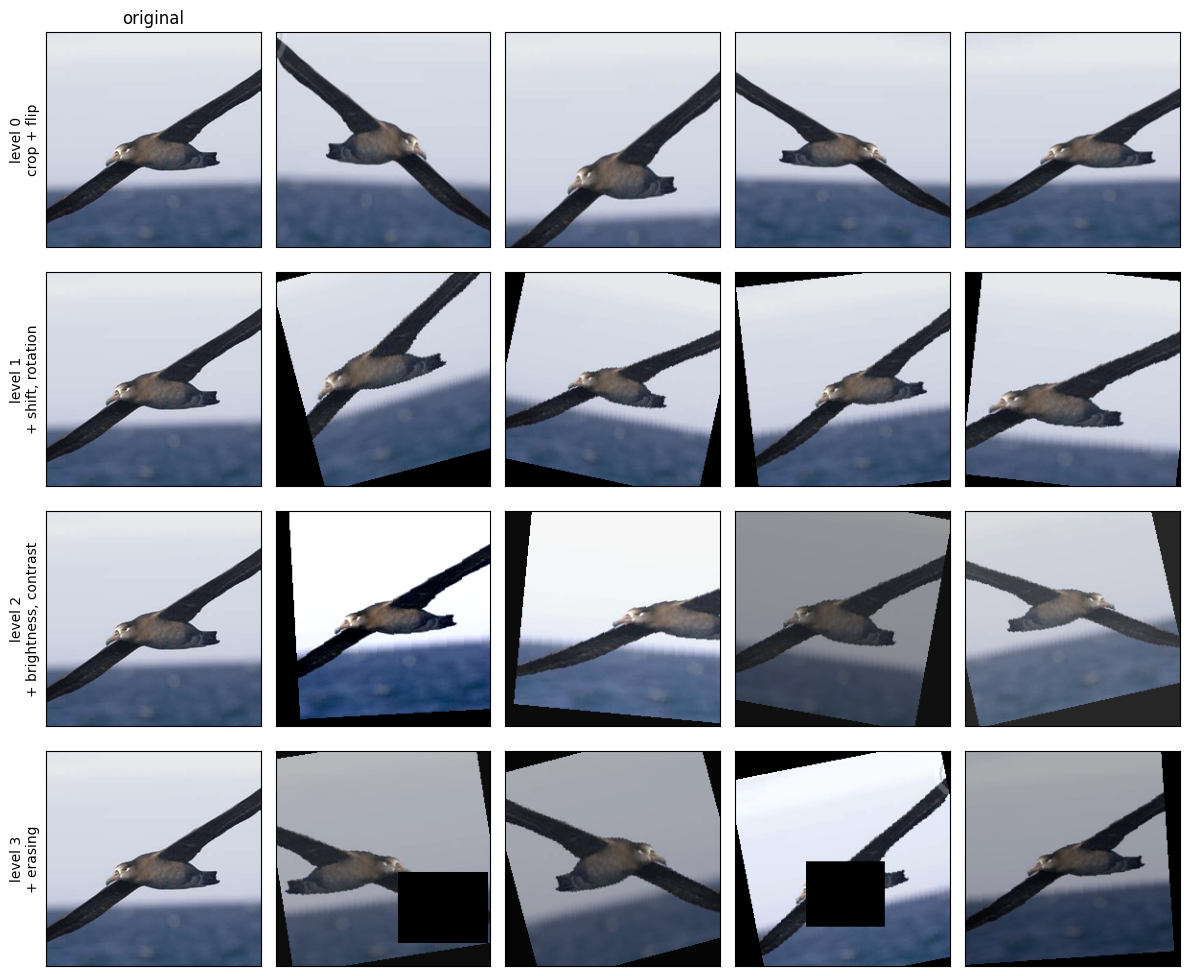

In [10]:
torch.manual_seed(SPLIT_SEED)
demo_image = images[labeled_df.index[0]]

fig, axes = plt.subplots(
    len(AUG_LEVEL_NAMES), 5, figsize=(12, 2.5 * len(AUG_LEVEL_NAMES))
)
for level, row_axes in enumerate(axes):
    transform = make_transform(level)
    row_axes[0].imshow(make_transform(-1)(demo_image).permute(1, 2, 0))
    row_axes[0].set_ylabel(f"level {level}\n{AUG_LEVEL_NAMES[level]}")
    for ax in row_axes[1:]:
        ax.imshow(transform(demo_image).permute(1, 2, 0))
    for ax in row_axes:
        ax.set_xticks([])
        ax.set_yticks([])
axes[0, 0].set_title("original")
fig.tight_layout()
plt.show()

## Модели и итеративная разморозка

Каждую сеть делю на 5 групп от головы к началу сети. В режимах с разморозкой на эпохе k обучаются первые k групп, остальные заморожены (у замороженных BatchNorm тоже не обновляет статистики). С 5-й эпохи обучается вся сеть.

Адаптивный lr устроен так:

- у каждой группы свой lr: у головы 5e-4, у каждой следующей группы в 2 раза меньше. Ранние слои учат общие признаки вроде краёв и текстур, их нужно менять меньше всего;
- когда группа размораживается, её lr в течение эпохи линейно растёт от нуля, чтобы первые шаги AdamW не сломали предобученные веса;
- после полной разморозки lr всех групп затухает по косинусу.

В `baseline` вся сеть с первой эпохи учится с одним постоянным lr 1e-4.

Значения lr подбирал на пробных запусках ResNet-50:

- baseline с lr 3e-4 нестабилен: точность на валидации доходила до 0.79 и потом проваливалась до 0.61, с 1e-4 обучение ровное;
- в разморозке множитель 0.3 между группами оказался слишком маленьким, первые слои почти не учились. С множителем 0.5 стало немного лучше;
- lr головы 1e-3 давал на 2-3% хуже, чем 5e-4.

In [11]:
def build_model(
    arch: str, device: torch.device, pretrained: bool = True
) -> tuple[nn.Module, dict[str, list[nn.Module]]]:
    if arch == "resnet50":
        weights = models.ResNet50_Weights.IMAGENET1K_V2
        net = models.resnet50()
    elif arch == "efficientnet_b7":
        weights = models.EfficientNet_B7_Weights.IMAGENET1K_V1
        net = models.efficientnet_b7()
    elif arch == "efficientnet_v2_s":
        weights = models.EfficientNet_V2_S_Weights.IMAGENET1K_V1
        net = models.efficientnet_v2_s()
    else:
        raise ValueError(f"Unknown architecture: {arch}")
    if pretrained:
        net.load_state_dict(weights.get_state_dict(progress=False))

    # Groups go from the classifier to the stem, in the unfreezing order.
    if arch == "resnet50":
        net.fc = nn.Linear(net.fc.in_features, num_classes)
        groups = {
            "fc": [net.fc],
            "layer4": [net.layer4],
            "layer3": [net.layer3],
            "layer2": [net.layer2],
            "stem + layer1": [net.conv1, net.bn1, net.layer1],
        }
    else:
        head = net.classifier[-1]
        net.classifier[-1] = nn.Linear(head.in_features, num_classes)
        # features[0] is the stem, the last item is the final 1x1 conv,
        # everything in between are MBConv / FusedMBConv stages.
        stages = list(net.features.children())
        last = len(stages) - 2
        first = "stage 1" if last == 6 else f"stages 1-{last - 5}"
        groups = {
            "classifier": [net.classifier],
            f"stage {last} + head conv": stages[last:],
            f"stages {last - 2}-{last - 1}": stages[last - 2:last],
            f"stages {last - 4}-{last - 3}": stages[last - 4:last - 2],
            f"stem + {first}": stages[:last - 4],
        }

    grouped = [
        id(param)
        for modules in groups.values()
        for param in group_parameters(modules)
    ]
    assert len(grouped) == len(set(grouped)) == len(list(net.parameters()))
    net = net.to(device, memory_format=torch.channels_last)
    return net, groups


def group_parameters(modules: list[nn.Module]) -> list[nn.Parameter]:
    return [param for module in modules for param in module.parameters()]


def scheduled_lr(
    depth: int, epoch: int, epoch_progress: float, num_groups: int
) -> float:
    if depth > epoch:
        return 0.0
    lr = HEAD_LR * LR_DECAY ** depth
    # Cosine decay starts once the whole network is unfrozen.
    full_epoch = num_groups - 1
    decay_progress = max(0, epoch - full_epoch) / (EPOCHS - full_epoch)
    lr *= 0.5 * (1 + math.cos(math.pi * decay_progress))
    # The group unfrozen at this epoch warms up linearly from zero.
    if depth == epoch and epoch > 0:
        lr *= epoch_progress
    return lr

In [12]:
group_rows = []
for arch in ARCHS:
    preview_net, preview_groups = build_model(
        arch, torch.device("cpu"), pretrained=False
    )
    total = sum(p.numel() for p in preview_net.parameters())
    trainable = 0
    for depth, (name, modules) in enumerate(preview_groups.items()):
        size = sum(p.numel() for p in group_parameters(modules))
        trainable += size
        group_rows.append(
            {
                "model": ARCH_TITLES[arch],
                "epoch": depth + 1,
                "unfrozen group": name,
                "params, M": size / 1e6,
                "trainable, %": 100 * trainable / total,
                "lr": HEAD_LR * LR_DECAY ** depth,
            }
        )
    del preview_net, preview_groups

display(
    pd.DataFrame(group_rows)
    .set_index(["model", "epoch"])
    .style.format(
        {"params, M": "{:.2f}", "trainable, %": "{:.1f}", "lr": "{:.1e}"}
    )
)

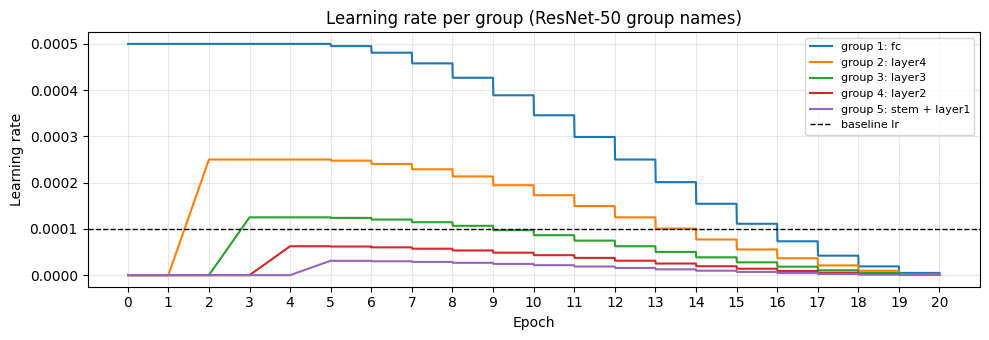

In [13]:
steps_per_epoch = math.ceil(len(labeled_df) / BATCH_SIZE)
epoch_progress = np.arange(1, steps_per_epoch + 1) / steps_per_epoch
resnet_group_names = [
    row["unfrozen group"] for row in group_rows if row["model"] == "ResNet-50"
]

fig, ax = plt.subplots(figsize=(10, 3.5))
for depth, name in enumerate(resnet_group_names):
    schedule = [
        scheduled_lr(depth, epoch, progress, len(resnet_group_names))
        for epoch in range(EPOCHS)
        for progress in epoch_progress
    ]
    ax.plot(np.arange(1, len(schedule) + 1) / steps_per_epoch, schedule,
            label=f"group {depth + 1}: {name}")
ax.axhline(BASE_LR, color="black", ls="--", lw=1, label="baseline lr")
ax.set(
    xlabel="Epoch",
    ylabel="Learning rate",
    title="Learning rate per group (ResNet-50 group names)",
    xticks=range(EPOCHS + 1),
)
ax.grid(alpha=0.3)
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

## Обучение

- `make_batch` собирает батч из картинок в памяти, переносит его на GPU и применяет аугментации текущего уровня;
- `predict_proba` считает вероятности классов на центральном кропе;
- `Experiment` обучает одну модель в одном режиме: разморозка, lr, аугментации, псевдометки и запоминание лучшей по валидации эпохи;
- `train_modes` прогоняет все 4 режима для одной архитектуры и одного сида.

Псевдолейблинг:

- после 10-й эпохи модель размечает весь неразмеченный пул, в псевдо-набор попадают картинки, где уверенность модели не меньше 0.9;
- после 15-й эпохи пул размечается заново уже дообученной моделью;
- псевдо-набор добавляется к размеченным картинкам с тем же весом в лоссе.

Порог 0.9 выбрал по пробному запуску: на 10-й эпохе он пропускал около 57% пула с точностью меток 93%. При пороге 0.7 проходило 75% картинок, но точность падала до 87%, для 200 классов это слишком много шума.

Режимы `augment` и `pseudo` до 10-й эпохи совпадают полностью, поэтому `pseudo` стартует с копии `augment` после 10-й эпохи. В момент начала псевдолейблинга у двух режимов одинаковые веса, и разница между ними получается только от псевдометок.

Обучение идёт сразу на двух GPU: на каждую карту свой поток, который берёт из очереди очередную пару (архитектура, сид). Сид задаёт инициализацию головы и порядок батчей. Из-за параллельного запуска и недетерминированных ядер cuDNN повторный запуск даёт немного другие числа, этот разброс как раз виден по std между сидами.

In [14]:
@torch.inference_mode()
def predict_proba(
    net: nn.Module, indices: np.ndarray, device: torch.device
) -> np.ndarray:
    # Inference stays in float32: in float16 EfficientNetV2 sometimes
    # overflowed to inf on validation, which turned probabilities into NaN.
    net.eval()
    probs = []
    for start in range(0, len(indices), EVAL_BATCH_SIZE):
        batch = make_batch(indices[start:start + EVAL_BATCH_SIZE], -1, device)
        probs.append(net(batch).softmax(1).cpu())
    return torch.cat(probs).numpy()


def classification_scores(
    targets: np.ndarray, probs: np.ndarray
) -> dict[str, float]:
    predictions = probs.argmax(1)
    return {
        "loss": log_loss(targets, probs, labels=range(num_classes)),
        "accuracy": (predictions == targets).mean(),
        "macro_f1": f1_score(targets, predictions, average="macro"),
    }


def select_pseudo_labels(probs: np.ndarray) -> pd.DataFrame:
    candidates = pd.DataFrame(
        {
            "index": unlabeled_df.index,
            "label": probs.argmax(1),
            "confidence": probs.max(1),
            "true_label": unlabeled_df.label.to_numpy(),
        }
    )
    return candidates[candidates.confidence >= PSEUDO_THRESHOLD]

In [15]:
@dataclass
class RunResult:
    history: pd.DataFrame
    best_epoch: int
    test_probs: np.ndarray
    pseudo_rounds: pd.DataFrame | None
    train_time: float


# Model creation uses the global RNG (head initialization) and downloads
# weights to a shared cache, so parallel workers do it one at a time.
model_init_lock = threading.Lock()


class Experiment:
    def __init__(
        self, arch: str, mode: str, seed: int, device: torch.device
    ) -> None:
        self.arch = arch
        self.mode = mode
        self.seed = seed
        self.device = device
        with model_init_lock:
            torch.manual_seed(seed)
            self.net, self.groups = build_model(arch, device)
        if mode == "baseline":
            param_groups = [
                {"params": list(self.net.parameters()), "lr": BASE_LR}
            ]
        else:
            # Deeper groups get smaller learning rates (discriminative lr).
            param_groups = [
                {
                    "params": group_parameters(modules),
                    "lr": HEAD_LR * LR_DECAY ** depth,
                }
                for depth, modules in enumerate(self.groups.values())
            ]
        self.optimizer = torch.optim.AdamW(
            param_groups, weight_decay=WEIGHT_DECAY
        )
        self.scaler = torch.amp.GradScaler(device.type, enabled=USE_AMP)
        self.history = []
        self.best_accuracy = -1.0
        self.best_epoch = 0
        self.best_state = None
        self.pseudo = None
        self.pseudo_rounds = []
        self.train_time = 0.0

    def set_stage(self, epoch: int) -> None:
        self.net.train()
        if self.mode == "baseline":
            return
        for depth, modules in enumerate(self.groups.values()):
            for module in modules:
                module.requires_grad_(depth <= epoch)
                # Frozen BatchNorm layers keep their ImageNet statistics.
                module.train(depth <= epoch)

    def set_lr(self, epoch: int, epoch_progress: float) -> None:
        if self.mode == "baseline":
            return
        for depth, group in enumerate(self.optimizer.param_groups):
            group["lr"] = scheduled_lr(
                depth, epoch, epoch_progress, len(self.groups)
            )

    def epoch_data(self) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
        indices = labeled_df.index.to_numpy()
        targets = labeled_df.label.to_numpy()
        weights = np.ones(len(indices), dtype=np.float32)
        if self.pseudo is not None:
            indices = np.concatenate([indices, self.pseudo["index"]])
            targets = np.concatenate([targets, self.pseudo.label])
            weights = np.concatenate(
                [weights, np.full(len(self.pseudo), PSEUDO_WEIGHT)]
            )
        return indices, targets, weights.astype(np.float32)

    def fit_epoch(self, epoch: int) -> None:
        start = time.time()
        self.set_stage(epoch)
        indices, targets, weights = self.epoch_data()
        rng = np.random.default_rng(1000 * self.seed + epoch)
        order = rng.permutation(len(indices))
        level = augmentation_level(epoch, self.mode)
        num_steps = math.ceil(len(order) / BATCH_SIZE)
        total_loss, total_weight = 0.0, 0.0
        for step in range(num_steps):
            batch_ids = order[step * BATCH_SIZE:(step + 1) * BATCH_SIZE]
            self.set_lr(epoch, (step + 1) / num_steps)
            batch = make_batch(indices[batch_ids], level, self.device)
            batch_targets = torch.as_tensor(
                targets[batch_ids], device=self.device
            )
            batch_weights = torch.as_tensor(
                weights[batch_ids], device=self.device
            )
            with torch.autocast(
                self.device.type, dtype=torch.float16, enabled=USE_AMP
            ):
                logits = self.net(batch)
            losses = nn.functional.cross_entropy(
                logits.float(), batch_targets, reduction="none"
            )
            loss = (losses * batch_weights).sum() / batch_weights.sum()
            self.optimizer.zero_grad(set_to_none=True)
            self.scaler.scale(loss).backward()
            self.scaler.step(self.optimizer)
            self.scaler.update()
            total_loss += loss.item() * batch_weights.sum().item()
            total_weight += batch_weights.sum().item()

        val_probs = predict_proba(
            self.net, val_df.index.to_numpy(), self.device
        )
        scores = classification_scores(val_df.label.to_numpy(), val_probs)
        self.history.append(
            {
                "epoch": epoch + 1,
                "train_loss": total_loss / total_weight,
                "val_loss": scores["loss"],
                "val_accuracy": scores["accuracy"],
                "val_macro_f1": scores["macro_f1"],
                "pseudo_count": 0 if self.pseudo is None else len(self.pseudo),
            }
        )
        if scores["accuracy"] > self.best_accuracy:
            self.best_accuracy = scores["accuracy"]
            self.best_epoch = epoch + 1
            self.best_state = {
                key: value.detach().cpu().clone()
                for key, value in self.net.state_dict().items()
            }
        self.train_time += time.time() - start

    def update_pseudo_labels(self, epoch: int) -> None:
        start = time.time()
        probs = predict_proba(
            self.net, unlabeled_df.index.to_numpy(), self.device
        )
        self.pseudo = select_pseudo_labels(probs)
        self.pseudo_rounds.append(
            {
                "after_epoch": epoch,
                "pool_accuracy": (
                    probs.argmax(1) == unlabeled_df.label.to_numpy()
                ).mean(),
                "selected": len(self.pseudo),
                "selected_share": len(self.pseudo) / len(unlabeled_df),
                "pseudo_accuracy": (
                    self.pseudo.label == self.pseudo.true_label
                ).mean(),
            }
        )
        self.train_time += time.time() - start

    def finish(self) -> RunResult:
        self.net.load_state_dict(self.best_state)
        test_probs = predict_proba(
            self.net, test_df.index.to_numpy(), self.device
        )
        rounds = None
        if self.pseudo_rounds:
            rounds = pd.DataFrame(self.pseudo_rounds)
        return RunResult(
            history=pd.DataFrame(self.history),
            best_epoch=self.best_epoch,
            test_probs=test_probs,
            pseudo_rounds=rounds,
            train_time=self.train_time,
        )

In [16]:
def train_modes(
    arch: str, seed: int, device: torch.device
) -> dict[str, RunResult]:
    results = {}
    for mode in ("baseline", "unfreeze"):
        experiment = Experiment(arch, mode, seed, device)
        for epoch in range(EPOCHS):
            experiment.fit_epoch(epoch)
        results[mode] = experiment.finish()
        del experiment
        torch.cuda.empty_cache()

    # augment and pseudo share every epoch before the first pseudo-labeling,
    # so the pseudo branch is a copy of the augment run at that point.
    trunk = Experiment(arch, "augment", seed, device)
    for epoch in range(PSEUDO_UPDATE_EPOCHS[0]):
        trunk.fit_epoch(epoch)
    student = copy.deepcopy(trunk)
    student.mode = "pseudo"
    for epoch in range(PSEUDO_UPDATE_EPOCHS[0], EPOCHS):
        trunk.fit_epoch(epoch)
    results["augment"] = trunk.finish()
    del trunk
    torch.cuda.empty_cache()

    for epoch in range(PSEUDO_UPDATE_EPOCHS[0], EPOCHS):
        if epoch in PSEUDO_UPDATE_EPOCHS:
            student.update_pseudo_labels(epoch)
        student.fit_epoch(epoch)
    results["pseudo"] = student.finish()
    return results


def result_path(arch: str, seed: int) -> Path:
    return RESULTS_DIR / f"{arch}_seed{seed}.pkl"


def device_worker(device: torch.device, jobs: queue.Queue) -> None:
    while True:
        try:
            arch, seed = jobs.get_nowait()
        except queue.Empty:
            return
        start = time.time()
        pd.to_pickle(train_modes(arch, seed, device), result_path(arch, seed))
        print(
            f"{ARCH_TITLES[arch]}, seed {seed}: done on {device} "
            f"in {(time.time() - start) / 60:.0f} min",
            flush=True,
        )

In [17]:
RESULTS_DIR.mkdir(exist_ok=True)
pending_jobs = [
    (arch, seed)
    for arch in ARCHS
    for seed in SEEDS
    if not result_path(arch, seed).exists()
]
# The slowest model goes first, so the devices finish at about the same time.
pending_jobs.sort(key=lambda job: job[0] != "efficientnet_b7")
job_queue = queue.Queue()
for job in pending_jobs:
    job_queue.put(job)

with ThreadPoolExecutor(len(DEVICES)) as executor:
    workers = [
        executor.submit(device_worker, device, job_queue) for device in DEVICES
    ]
    for worker in workers:
        worker.result()

all_runs: dict[str, dict[tuple[str, int], RunResult]] = {}
for arch in ARCHS:
    all_runs[arch] = {}
    for seed in SEEDS:
        for mode, result in pd.read_pickle(result_path(arch, seed)).items():
            all_runs[arch][mode, seed] = result

Downloading: "https://download.pytorch.org/models/efficientnet_b7_lukemelas-c5b4e57e.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b7_lukemelas-c5b4e57e.pth
EfficientNet-B7, seed 1: done on cuda:1 in 88 min
EfficientNet-B7, seed 0: done on cuda:0 in 91 min
Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth
ResNet-50, seed 0: done on cuda:0 in 28 min
ResNet-50, seed 1: done on cuda:0 in 28 min
ResNet-50, seed 2: done on cuda:0 in 28 min
Downloading: "https://download.pytorch.org/models/efficientnet_v2_s-dd5fe13b.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_v2_s-dd5fe13b.pth
EfficientNet-B7, seed 2: done on cuda:1 in 87 min
EfficientNetV2-S, seed 1: done on cuda:1 in 33 min
EfficientNetV2-S, seed 0: done on cuda:0 in 34 min
EfficientNetV2-S, seed 2: done on cuda:1 in 30 min


In [18]:
def collect_scores(
    arch: str, runs: dict[tuple[str, int], RunResult]
) -> pd.DataFrame:
    rows = []
    for (mode, seed), result in runs.items():
        test_scores = classification_scores(
            test_df.label.to_numpy(), result.test_probs
        )
        rows.append(
            {
                "model": ARCH_TITLES[arch],
                "mode": mode,
                "seed": seed,
                "best_epoch": result.best_epoch,
                "val_accuracy": result.history.val_accuracy.max(),
                "test_accuracy": test_scores["accuracy"],
                "test_macro_f1": test_scores["macro_f1"],
                "time, min": result.train_time / 60,
            }
        )
    return pd.DataFrame(rows)


def mean_std_table(scores: pd.DataFrame, columns: list[str]) -> pd.DataFrame:
    grouped = scores.groupby(["model", "mode"], sort=False)[columns]
    means = grouped.mean().map("{:.4f}".format)
    stds = grouped.std().map("{:.4f}".format)
    return means + " ± " + stds


summary = pd.concat(
    [collect_scores(arch, runs) for arch, runs in all_runs.items()],
    ignore_index=True,
)
display(
    mean_std_table(
        summary, ["best_epoch", "val_accuracy", "test_accuracy", "time, min"]
    )
)

best_epoch     val_accuracy    test_accuracy  \
model            mode                                                           
ResNet-50        baseline  17.0000 ± 3.4641  0.7696 ± 0.0018  0.7479 ± 0.0060   
                 unfreeze  14.3333 ± 3.0551  0.7882 ± 0.0020  0.7656 ± 0.0022   
                 augment   17.3333 ± 2.0817  0.7843 ± 0.0111  0.7641 ± 0.0046   
                 pseudo    18.6667 ± 0.5774  0.7911 ± 0.0115  0.7777 ± 0.0021   
EfficientNet-B7  baseline  14.0000 ± 2.0000  0.7733 ± 0.0102  0.7382 ± 0.0087   
                 unfreeze  17.3333 ± 4.6188  0.7577 ± 0.0076  0.7465 ± 0.0065   
                 augment   18.3333 ± 1.1547  0.7885 ± 0.0072  0.7669 ± 0.0015   
                 pseudo    17.3333 ± 1.5275  0.8063 ± 0.0024  0.7861 ± 0.0024   
EfficientNetV2-S baseline  10.3333 ± 1.5275  0.7973 ± 0.0015  0.7697 ± 0.0031   
                 unfreeze  16.6667 ± 2.0817  0.8264 ± 0.0026  0.7933 ± 0.0071   
                 augment   19.3333 ± 0.5774  0.8202 ± 0.0037  0.7967 ± 0.0018   
                 pseudo    19.0000 ± 1.0000  0.8374 ± 0.0018  0.8164 ± 0.0051   

                                  time, min  
model            mode                        
ResNet-50        baseline   6.4371 ± 0.0441  
                 unfreeze   6.0096 ± 0.0240  
                 augment    7.5563 ± 0.1136  
                 pseudo    10.2239 ± 0.0285  
EfficientNet-B7  baseline  22.8041 ± 0.5810  
                 unfreeze  20.5667 ± 0.5450  
                 augment   22.4542 ± 0.4726  
                 pseudo    30.4571 ± 0.6747  
EfficientNetV2-S baseline   7.3743 ± 0.2954  
                 unfreeze   6.9478 ± 0.3139  
                 augment    8.7712 ± 0.8266  
                 pseudo    12.2866 ± 1.1915

## Результаты

### Кривые обучения и матрицы ошибок

Для каждой архитектуры сверху кривые train loss, validation loss и validation accuracy: линия это среднее по 3 сидам, тень это std. Красные пунктиры отмечают эпохи, после которых обновляются псевдометки.

Снизу матрицы ошибок на тесте для каждого режима, просуммированные по сидам и нормированные по строкам. При 200 классах подписи не прочитать, поэтому смотрю на общую картину: насколько чистая диагональ и есть ли яркие пятна вне неё. Шкала обрезана на 0.3, чтобы были видны ошибки.

In [19]:
def plot_report(arch: str) -> None:
    runs = all_runs[arch]
    curves = pd.concat(
        [
            result.history.assign(mode=mode)
            for (mode, _), result in runs.items()
        ]
    )
    fig = plt.figure(figsize=(18, 9), layout="constrained")
    top, bottom = fig.subfigures(2, 1, height_ratios=[1, 1.1])
    curve_axes = top.subplots(1, 3)
    metrics = [
        ("train_loss", "Train loss"),
        ("val_loss", "Validation loss"),
        ("val_accuracy", "Validation accuracy"),
    ]
    for ax, (column, title) in zip(curve_axes, metrics):
        sns.lineplot(
            data=curves,
            x="epoch",
            y=column,
            hue="mode",
            palette=MODE_COLORS,
            errorbar="sd",
            ax=ax,
            legend=column == "val_accuracy",
        )
        ax.set(title=title, xlabel="Epoch", ylabel="")
        ax.set_xticks(range(1, EPOCHS + 1))
        ax.grid(alpha=0.3)
        for boundary in PSEUDO_UPDATE_EPOCHS:
            ax.axvline(boundary + 0.5, color="#d62728", ls=":", lw=1)
    curve_axes[0].set_yscale("log")
    curve_axes[1].set_yscale("log")

    matrix_axes = bottom.subplots(1, len(MODES))
    for ax, mode in zip(matrix_axes, MODES):
        # Confusion matrices are summed over seeds and normalized by rows.
        matrix = sum(
            confusion_matrix(
                test_df.label,
                runs[mode, seed].test_probs.argmax(1),
                labels=range(num_classes),
            )
            for seed in SEEDS
        )
        matrix = matrix / matrix.sum(1, keepdims=True)
        ax.imshow(matrix, cmap="Blues", vmin=0, vmax=0.3)
        accuracy = np.trace(matrix) / num_classes
        ax.set(
            title=f"{mode}, test (mean recall {accuracy:.3f})",
            xlabel="Predicted class",
        )
        ax.set_xticks([])
        ax.set_yticks([])
    matrix_axes[0].set_ylabel("True class")
    fig.suptitle(ARCH_TITLES[arch], fontsize=14)
    plt.show()

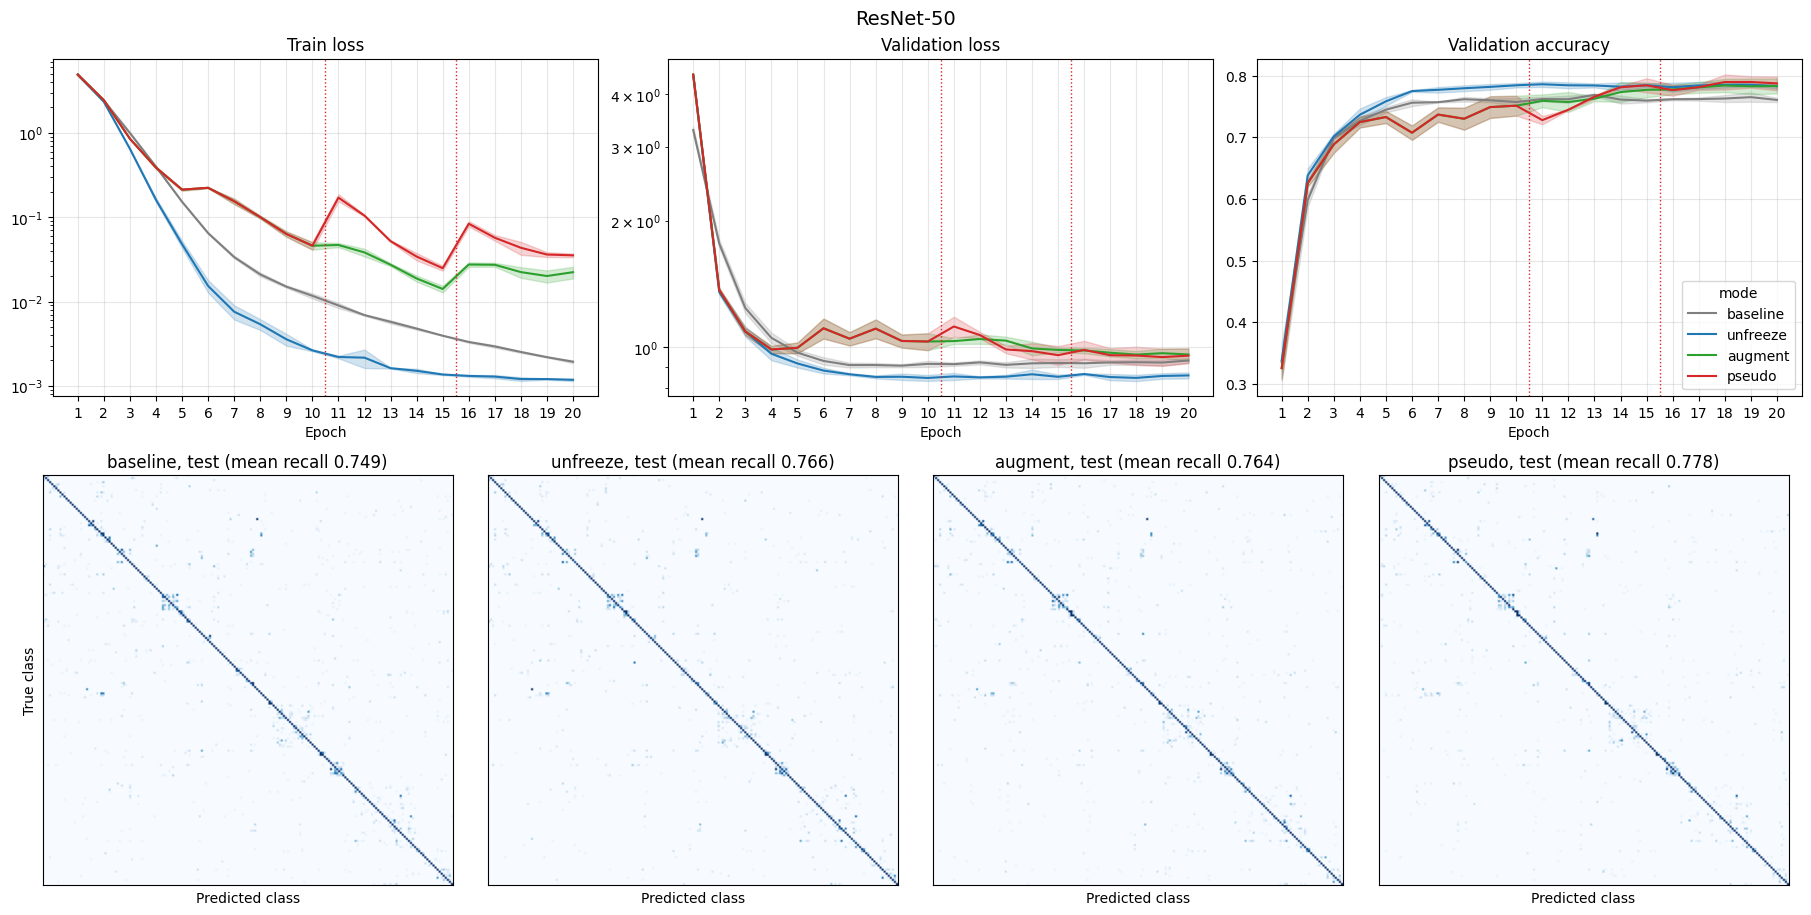

In [20]:
plot_report("resnet50")

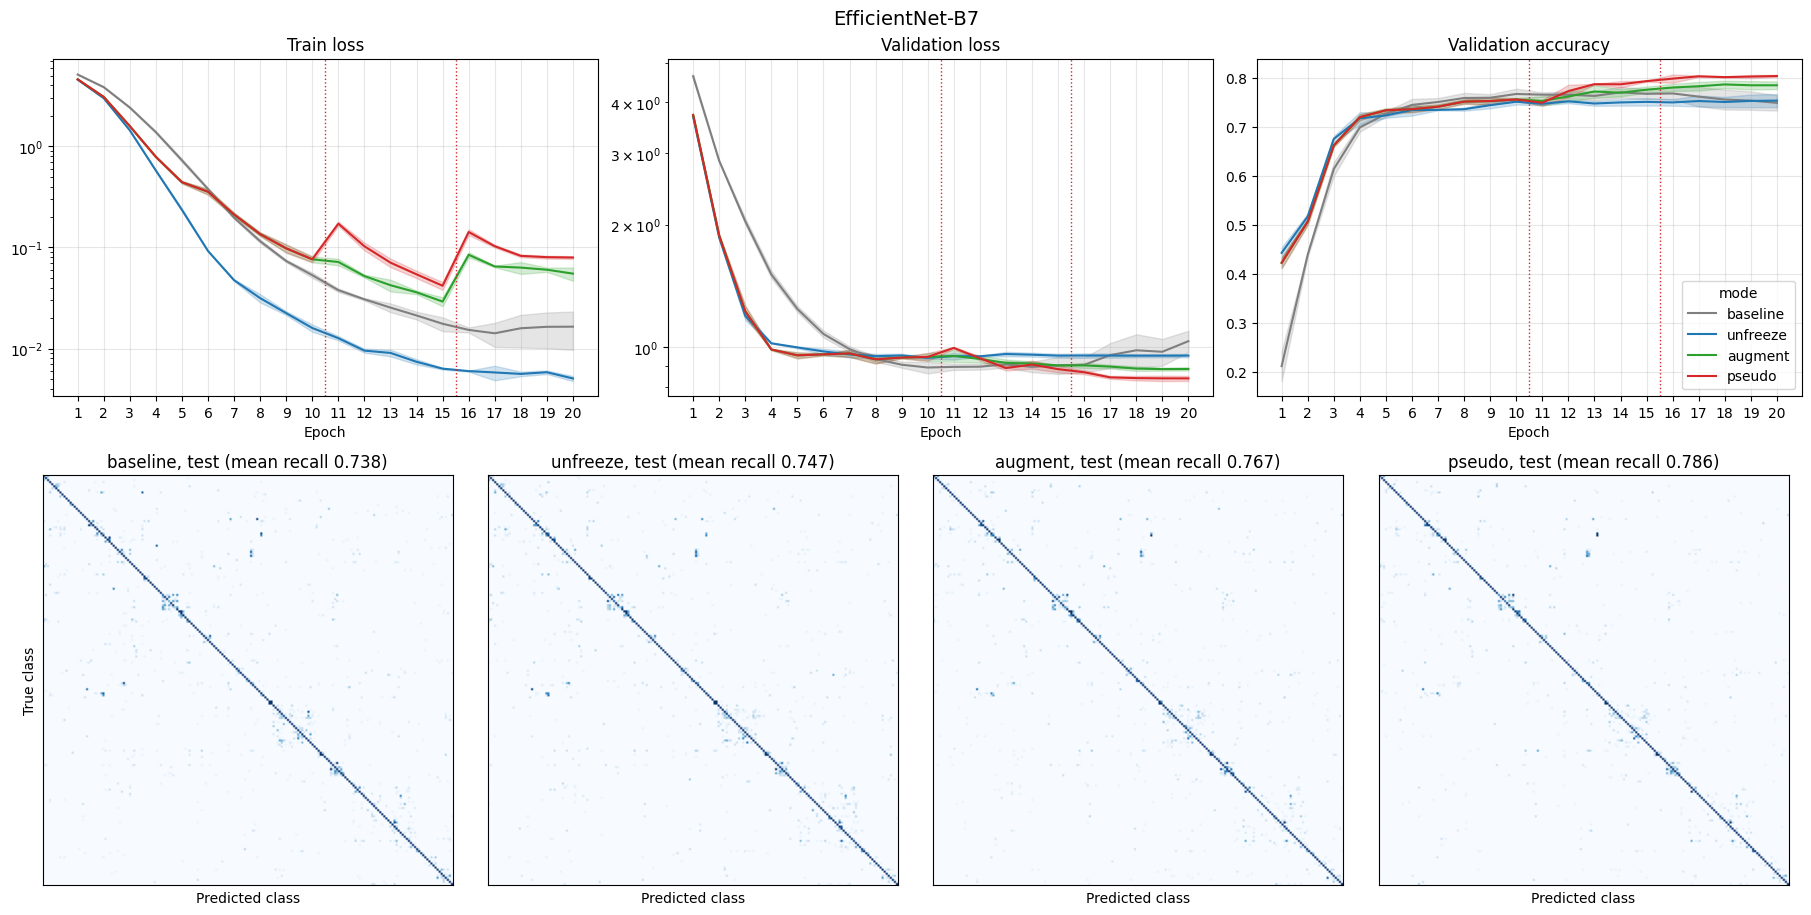

In [21]:
plot_report("efficientnet_b7")

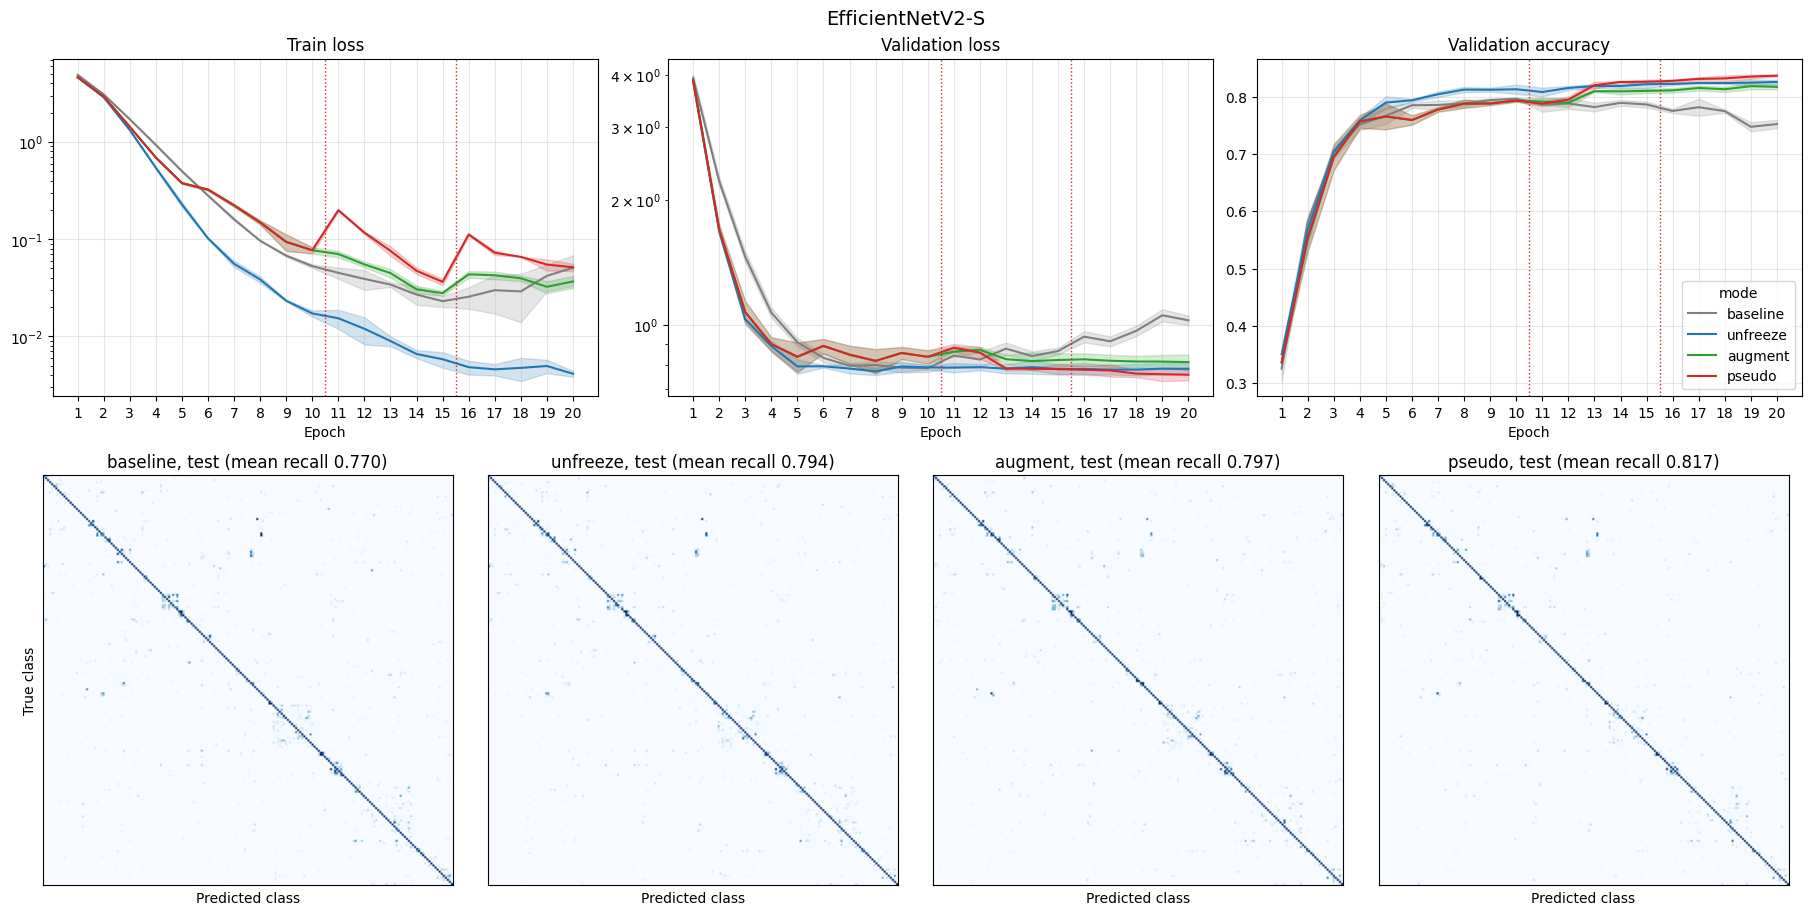

In [22]:
plot_report("efficientnet_v2_s")

Что видно по кривым:

- `baseline` переобучается. Train loss падает почти до нуля, а validation loss у EfficientNetV2-S и B7 после 13-16 эпохи начинает расти. У V2-S validation accuracy к концу проседает с 0.79 до 0.75, лучшая эпоха в среднем 10-я. С постоянным lr и без аугментаций сеть просто запоминает 19 картинок на класс.
- `unfreeze` сходится быстрее всех: validation accuracy выходит на плато у ResNet-50 к 6-й эпохе, у V2-S к 8-й, то есть почти сразу после разморозки всей сети. Validation loss у этого режима самый низкий и дальше почти не меняется, после разморозки cosine-расписание просто дотягивает веса. Скачков при разморозке новой группы нет, их убирает warmup.
- У `augment` train loss перестаёт падать на 6-й и 11-й эпохе и подскакивает на 16-й, когда включается RandomErasing. Train loss остаётся на порядок выше, чем у `unfreeze`, зато validation accuracy растёт до самого конца и лучшая эпоха почти всегда 17-20. Похоже, 20 эпох для этого режима мало.
- У `pseudo` после каждого обновления псевдометок (красные пунктиры) train loss резко растёт: в выборке появляется 2-3 тысячи новых картинок, часть меток в них неверная. Через 1-2 эпохи validation accuracy обгоняет `augment`, сильнее всего это видно у B7 и V2-S.
- Матрицы ошибок у всех режимов похожи: диагональ чистая, а ошибки собраны в пятна рядом с ней. В CUB номера классов идут по семействам (чайки, крачки, воробьи, мухоловки, славки стоят подряд), поэтому пятно у диагонали означает путаницу внутри одного семейства. От `baseline` к `pseudo` эти пятна заметно бледнеют.

### Итоговая таблица

In [23]:
final_table = mean_std_table(summary, ["test_accuracy", "test_macro_f1"])
mean_accuracy = summary.groupby(["model", "mode"], sort=False).test_accuracy
mean_accuracy = 100 * mean_accuracy.mean()
final_table["vs previous mode, pp"] = (
    mean_accuracy.groupby(level="model").diff().round(2)
)
final_table["vs baseline, pp"] = (
    mean_accuracy - mean_accuracy.groupby(level="model").transform("first")
).round(2)
display(final_table)

test_accuracy    test_macro_f1  \
model            mode                                         
ResNet-50        baseline  0.7479 ± 0.0060  0.7471 ± 0.0062   
                 unfreeze  0.7656 ± 0.0022  0.7639 ± 0.0014   
                 augment   0.7641 ± 0.0046  0.7614 ± 0.0048   
                 pseudo    0.7777 ± 0.0021  0.7751 ± 0.0019   
EfficientNet-B7  baseline  0.7382 ± 0.0087  0.7370 ± 0.0070   
                 unfreeze  0.7465 ± 0.0065  0.7451 ± 0.0065   
                 augment   0.7669 ± 0.0015  0.7644 ± 0.0021   
                 pseudo    0.7861 ± 0.0024  0.7826 ± 0.0024   
EfficientNetV2-S baseline  0.7697 ± 0.0031  0.7682 ± 0.0035   
                 unfreeze  0.7933 ± 0.0071  0.7906 ± 0.0073   
                 augment   0.7967 ± 0.0018  0.7937 ± 0.0028   
                 pseudo    0.8164 ± 0.0051  0.8134 ± 0.0052   

                           vs previous mode, pp  vs baseline, pp  
model            mode                                             
ResNet-50        baseline                   NaN             0.00  
                 unfreeze                  1.78             1.78  
                 augment                  -0.16             1.62  
                 pseudo                    1.37             2.99  
EfficientNet-B7  baseline                   NaN             0.00  
                 unfreeze                  0.84             0.84  
                 augment                   2.04             2.87  
                 pseudo                    1.92             4.80  
EfficientNetV2-S baseline                   NaN             0.00  
                 unfreeze                  2.36             2.36  
                 augment                   0.34             2.70  
                 pseudo                    1.97             4.67

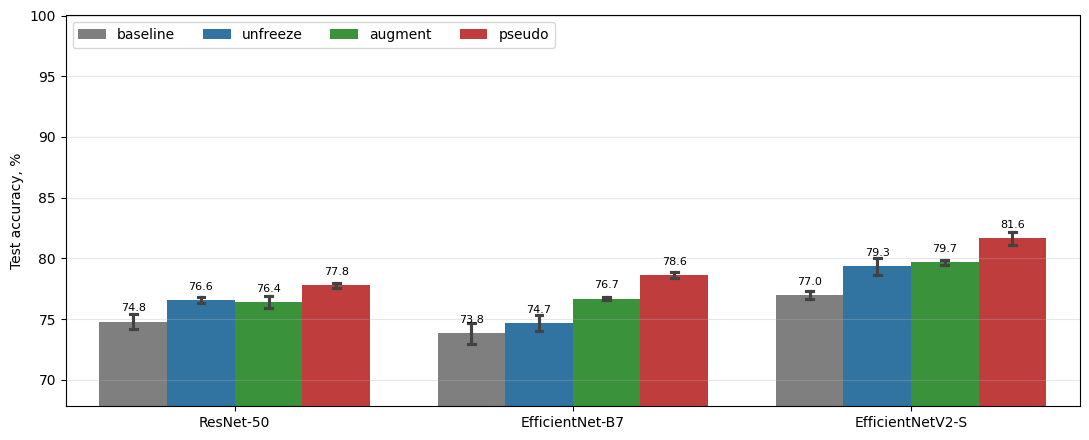

In [24]:
fig, ax = plt.subplots(figsize=(11, 4.5))
sns.barplot(
    data=summary.assign(accuracy=100 * summary.test_accuracy),
    x="model",
    y="accuracy",
    hue="mode",
    palette=MODE_COLORS,
    errorbar="sd",
    capsize=0.08,
    ax=ax,
)
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f", padding=6, fontsize=8)
low = 100 * summary.test_accuracy.min()
ax.set(xlabel="", ylabel="Test accuracy, %", ylim=(low - 5, 100))
ax.legend(ncols=4, loc="upper left")
ax.grid(axis="y", alpha=0.3)
fig.tight_layout()
plt.show()

По итоговой таблице:

- Архитектуры заметно различаются. Лучшая EfficientNetV2-S: 77.0% в `baseline` и 81.6% в `pseudo`. ResNet-50 и B7 идут почти вровень, в `pseudo` 77.8% и 78.6%. Std по сидам везде меньше 1 п.п., так что отрыв V2-S от остальных в `pseudo` на 3-4 п.п. явно больше шума.
- EfficientNet-B7 оказалась самой невыгодной. На 224 x 224 в `baseline` она даже хуже ResNet-50, а учится примерно в 3 раза дольше V2-S. B7 предобучали на входе 600 x 600, и на маленьких картинках её размер не помогает. При 19 картинках на класс 64 млн параметров скорее мешают.
- Итеративная разморозка даёт +1.8 п.п. ResNet-50 и +2.4 п.п. V2-S, у B7 всего +0.8. У B7 группы получились неравными: на 3-й эпохе размораживаются сразу стадии 5-6 с 36 млн параметров, и validation accuracy после этого почти не растёт. Возможно, такой большой кусок сети стоило размораживать в два шага.
- Итеративная аугментация сильнее всего помогла B7 (+2.0 п.п.), у V2-S прибавка +0.3, у ResNet-50 -0.2, это в пределах std. Самый сложный уровень работает только последние 5 эпох, и по кривым видно, что этот режим ещё не дообучился.
- Псевдолейблинг стабильно добавляет +1.4-2.0 п.п. всем трём сетям, это самая надёжная из трёх техник.
- Всего от `baseline` к `pseudo` прирост +3.0 п.п. у ResNet-50, +4.8 у B7 и +4.7 у V2-S. Macro F1 везде идёт за accuracy, потому что классы сбалансированы.
- Ожидания подтвердились. Я ждал 75-80%, ResNet-50 со всеми техниками дала 77.8%, V2-S 81.6%. До 84.5% из NTS-Net ResNet-50 не хватает 6.7 п.п., что вполне объяснимо вдвое меньшим входом и в полтора раза меньшей разметкой.

### Псевдолейблинг

Настоящие метки неразмеченного пула известны, поэтому можно проверить, насколько псевдометки правильные. В таблице для каждого раунда: точность модели на всём пуле, сколько картинок прошло порог 0.9, их доля в пуле и точность псевдометок среди них. Всё усреднено по сидам.

In [25]:
pseudo_rows = []
for arch, runs in all_runs.items():
    for seed in SEEDS:
        rounds = runs["pseudo", seed].pseudo_rounds
        pseudo_rows.append(rounds.assign(model=ARCH_TITLES[arch], seed=seed))
pseudo_table = (
    pd.concat(pseudo_rows)
    .groupby(["model", "after_epoch"], sort=False)
    [["pool_accuracy", "selected", "selected_share", "pseudo_accuracy"]]
    .mean()
)
display(
    pseudo_table.style.format(
        {
            "pool_accuracy": "{:.4f}",
            "selected": "{:.0f}",
            "selected_share": "{:.3f}",
            "pseudo_accuracy": "{:.4f}",
        }
    )
)

- После 10-й эпохи порог 0.9 проходят 55-64% пула, псевдометки верны на 92.6-94.1%. Это сильно выше общей точности модели на пуле (74-79%), то есть порог по уверенности хорошо отсекает ошибки.
- Ко второму раунду модель подросла: точность на пуле выросла на 2.4-3.3 п.п., а через порог проходит уже 70-78% пула. Точность псевдометок при этом упала до 90.3-92.0%, потому что в выборку попадают картинки потруднее.
- Даже с порогом 0.9 примерно каждая десятая псевдометка неверная, во втором раунде это 210-260 картинок. Пользы всё равно больше: обучающая выборка почти удваивается, с 3831 до 6500-6800 картинок.
- У V2-S через порог проходит больше всего картинок почти с той же точностью, что у B7. У ResNet-50 псевдометки менее точные, и прирост от псевдолейблинга у неё самый маленький (+1.4 п.п.).

### Ошибки лучшей модели

Беру лучшую по средней accuracy на тесте конфигурацию и смотрю её ошибки на первом сиде: самые частые пары перепутанных видов, самые трудные и самые лёгкие классы и картинки, на которых модель ошиблась увереннее всего.

In [26]:
best_model, best_mode = mean_accuracy.idxmax()
best_arch = {title: arch for arch, title in ARCH_TITLES.items()}[best_model]
best_probs = all_runs[best_arch][best_mode, SEEDS[0]].test_probs
errors = test_df.assign(
    predicted=best_probs.argmax(1), confidence=best_probs.max(1)
).query("label != predicted")
errors["predicted_name"] = errors.predicted.map(dict(enumerate(class_names)))
print(
    f"{best_model}, {best_mode}, seed {SEEDS[0]}: "
    f"{len(errors)} errors out of {len(test_df)} test images"
)
display(
    errors.groupby(["class_name", "predicted_name"])
    .size()
    .nlargest(10)
    .rename("errors")
    .to_frame()
)

EfficientNetV2-S, pseudo, seed 0: 526 errors out of 2947 test images


,,errors
class_name,predicted_name,
Great Grey Shrike,Loggerhead Shrike,9
Annas Hummingbird,Ruby throated Hummingbird,6
Herring Gull,California Gull,6
Clay colored Sparrow,Brewers Sparrow,5
Cliff Swallow,Barn Swallow,5
Glaucous winged Gull,California Gull,5
Olive sided Flycatcher,Western Wood Pewee,5
Western Gull,California Gull,5
Acadian Flycatcher,Yellow bellied Flycatcher,4


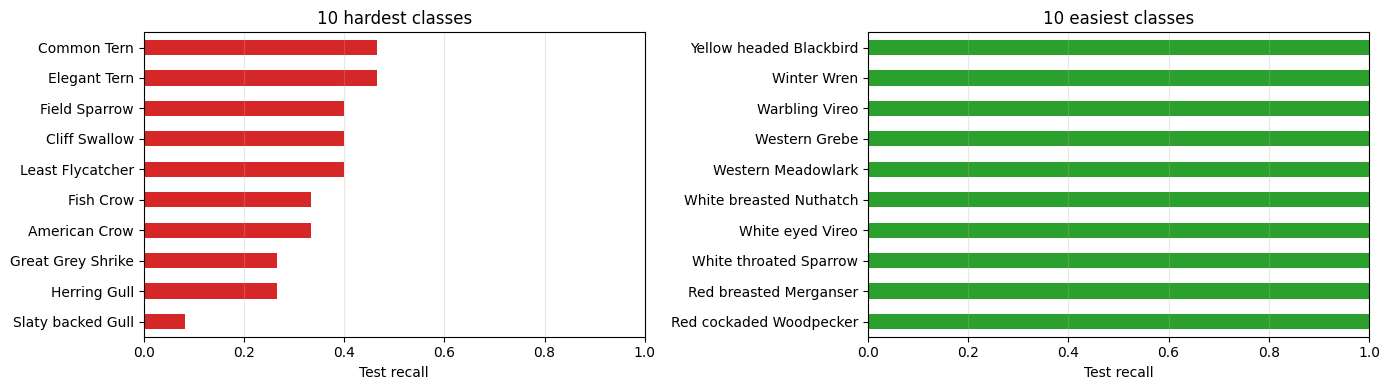

In [27]:
class_recall = (
    test_df.assign(correct=best_probs.argmax(1) == test_df.label)
    .groupby("class_name")
    .correct.mean()
    .sort_values()
)
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
class_recall.head(10).plot.barh(ax=axes[0], color="#d62728")
class_recall.tail(10).plot.barh(ax=axes[1], color="#2ca02c")
axes[0].set(title="10 hardest classes", xlabel="Test recall", ylabel="")
axes[1].set(title="10 easiest classes", xlabel="Test recall", ylabel="")
for ax in axes:
    ax.set_xlim(0, 1)
    ax.grid(axis="x", alpha=0.3)
fig.tight_layout()
plt.show()

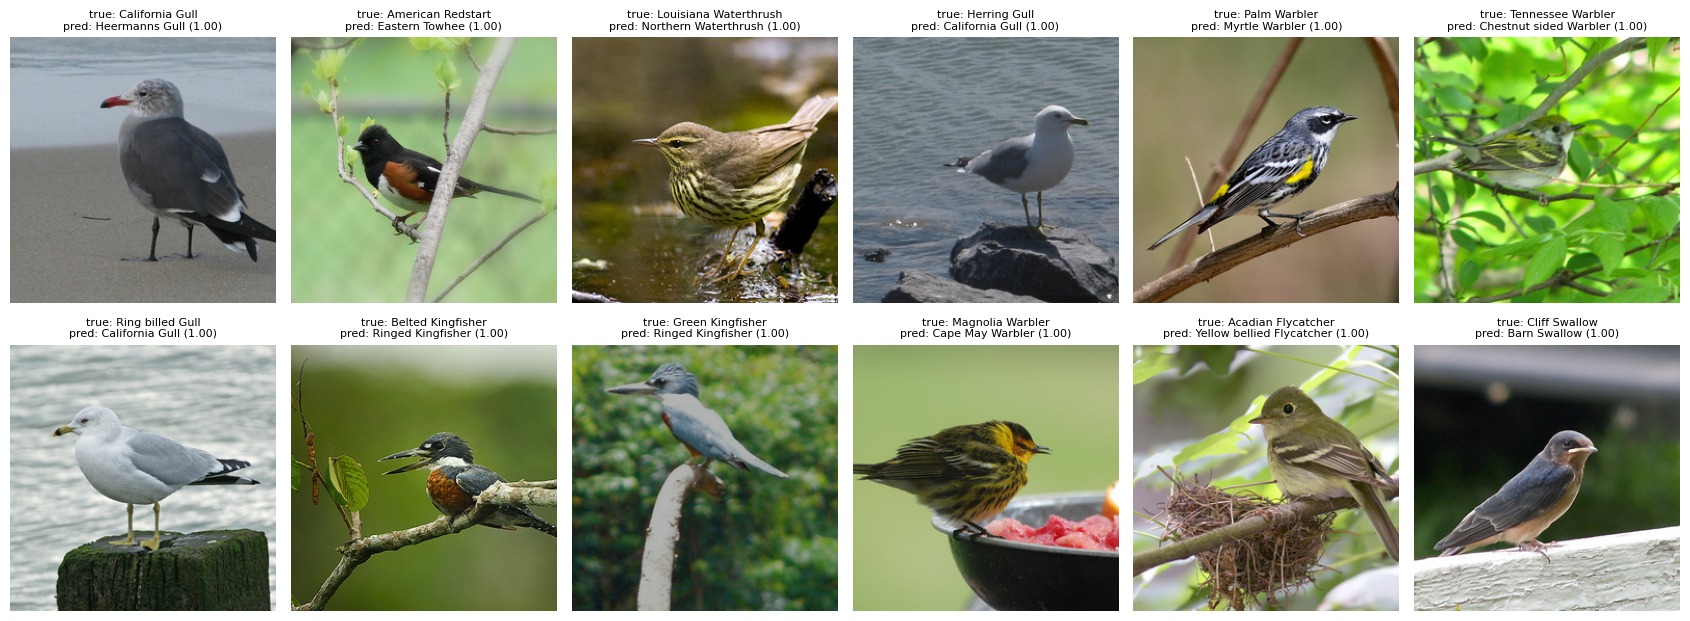

In [28]:
fig, axes = plt.subplots(2, 6, figsize=(17, 6.5))
for ax, row in zip(
    axes.flat, errors.nlargest(len(axes.flat), "confidence").itertuples()
):
    ax.imshow(images[row.Index].permute(1, 2, 0))
    ax.set_title(
        f"true: {row.class_name}\npred: {row.predicted_name} "
        f"({row.confidence:.2f})",
        fontsize=8,
    )
    ax.axis("off")
fig.tight_layout()
plt.show()

- Почти все частые ошибки приходятся на виды, которые и человек без определителя не различит: серый и американский сорокопуты, колибри Анны и рубиновогорлый колибри, несколько видов чаек, американская ворона и ворон. Они отличаются размером, голосом или мелкими деталями оперения, а на 224 x 224 мелкие детали частично пропадают.
- Среди самых трудных классов те же чайки, вороны, мухоловки и воробьи. У Slaty-backed Gull recall меньше 0.1. Самые лёгкие классы, наоборот, с яркой и необычной окраской: Painted Bunting, Green Jay, Summer Tanager. Recall 1.0 на тесте у многих классов, на графике просто 10 из них.
- Самые уверенные ошибки сделаны с вероятностью около 1.00, модель сильно переуверена. Для калибровки помогли бы label smoothing или temperature scaling.
- Часть этих ошибок, похоже, на совести разметки. На картинке с меткой American Redstart птица по окраске больше похожа на Eastern Towhee, а Palm Warbler выглядит как Myrtle Warbler, то есть модель ответила как раз то, что видно на фото. В CUB известны ошибки разметки, порядка 4% картинок, так что потолок точности на этом датасете ниже 100%.

## Выводы

- Обучил три архитектуры со слайда (ResNet-50, EfficientNet-B7, EfficientNetV2-S) в 4 режимах на 3 сидах и реализовал все три техники с занятия: итеративную разморозку с отдельным lr для каждой группы, итеративную аугментацию и псевдолейблинг с обновлением меток.
- Лучший результат у EfficientNetV2-S со всеми техниками: 81.6 ± 0.5% accuracy на тесте при 19 размеченных картинках на класс. ResNet-50 даёт 77.8%, B7 78.6%. Это попадает в ожидаемые 75-80% и даже выше для V2-S.
- Все техники вместе дают +3-5 п.п. к обычному fine-tuning. Самый стабильный вклад у псевдолейблинга (+1.4-2.0 п.п. у всех сетей), разморозка хорошо работает для ResNet-50 и V2-S, аугментация сильнее всего помогла B7.
- На CUB и входе 224 EfficientNet-B7 не окупается: она учится дольше всех, а обгоняет ResNet-50 всего на 0.8 п.п. в `pseudo`. Для такой задачи разумный выбор EfficientNetV2-S.
- Что можно улучшить: учить на 448 x 448, увеличить число эпох для режимов с аугментацией, попробовать мягкие псевдометки или порог по классам, добавить label smoothing против переуверенности.